# Group Exam GRA 41624 Deep Learning and Explainable AI

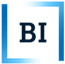

Course code and name: GRA 4162 Deep Learning and Explainable AI

Type of exam: Home exam

Start date: 13/11/2026 09:00

Finish date: 04/12/2026 12:00 

Term: Fall 2026

Weight in the total grade: 40%

To be answered in groups: 1-3 students

Allowed file types for answer paper: Jupyter notebook (.ipynb)

Separate attachment allowed: No

Number of files allowed to be uploaded: 1

### Deliverables and submission instructions

- Fill in all Code cells with Python code. Use comments in the code. Follow the instructions from the previous cell.

- Add Markdown cells if you need to add a Comment.

- Submit the notebook. Before you submit it, run the entire notebook to ensure all code is compiled correctly and results can be reproduced.

### Allowed aids

- You are allowed to use all the course materials.

- You are NOT allowed to use artificial intelligence tools in directly solving your exercises.

- You are NOT allowed to use help from people that are not in your project group.

In [27]:
#=======================================
# import packages
#=======================================
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator as TG
from tqdm.keras import TqdmCallback




### Exercise 1. GDP prediction with RNNs (35 points)

In this exercise, you will use historical US macroeconomic data from the Federal Reserve Economic Data (FRED) database. The dataset contains four macroeconomic variables: GDP, inflation, the unemployment rate, and money growth, observed over a specified period (period and frequency) and can be found here:

https://fred.stlouisfed.org/series/GDPC1

https://fred.stlouisfed.org/series/CPIAUCSL

https://fred.stlouisfed.org/series/unrate

https://fred.stlouisfed.org/series/M2SL/nMost

You will build several recurrent neural networks to predict GDP using univariate and multivariate inputs. Follow the instructions below and solve the exercise step by step.

#### 1 a) Load, preprocess, and visualize the data (5 points) 

Load the data from the attached file named 'US_macro_FRED.csv' and remove any missing values. Then, plot all variables against time.

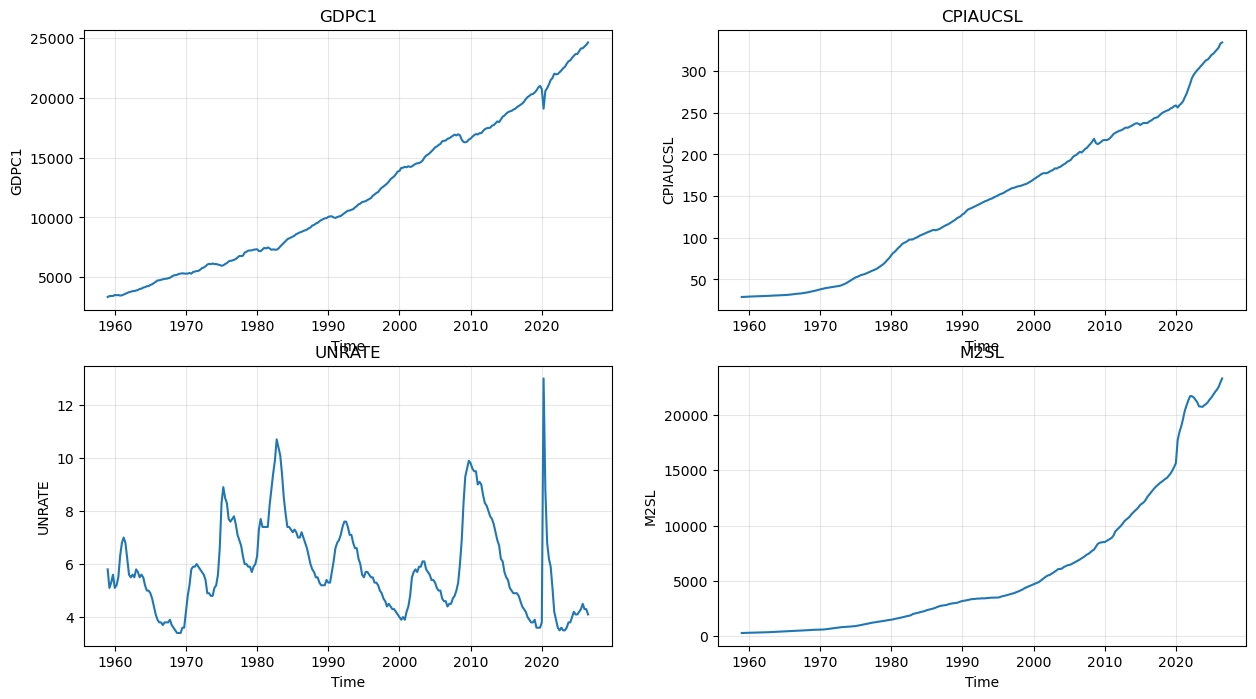

    observation_date      GDPC1  CPIAUCSL  UNRATE     M2SL
0         1959-01-01   3352.129    28.993     5.8    287.8
1         1959-04-01   3427.667    29.043     5.1    292.1
2         1959-07-01   3430.057    29.193     5.3    296.1
3         1959-10-01   3439.832    29.370     5.6    297.1
4         1960-01-01   3517.181    29.397     5.1    298.6
..               ...        ...       ...     ...      ...
266       2025-07-01  24112.966   323.235     4.3  22071.1
267       2025-10-01  24125.479   325.547     4.5  22268.4
268       2026-01-01  24274.383   328.114     4.3  22524.3
269       2026-04-01  24408.011   332.985     4.3  22928.9
270       2026-07-01  24611.077   334.414     4.1  23297.4

[271 rows x 5 columns]


In [17]:
#Load data
data_path = "US_macro_FRED.csv"

df = pd.read_csv(data_path)

#Convert date format
df["observation_date"] = pd.to_datetime(
    df["observation_date"],
    format="%m/%d/%y"
)
mask = df["observation_date"].dt.year > 2026
df.loc[mask, "observation_date"] -= pd.DateOffset(years=100)

#Remove missing value
df = df.dropna().reset_index(drop=True)

#Plot all variables against time

variables = ["GDPC1", "CPIAUCSL", "UNRATE", "M2SL"]

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

for ax, var in zip(axes.flatten(), variables):
    ax.plot(df["observation_date"], df[var])
    ax.set_title(var)
    ax.set_xlabel("Time")
    ax.set_ylabel(var)
    ax.grid(alpha=0.3)

plt.show()

print(df)

#### 1 b) Generate training data (5 points) 

- Using only the GDP data, define a univariate time series generator to predict the GDP value based on the four preceding periods.
- Using all the variables in the dataset, define a multivariate time series generator to create data instances for predicting the GDP value based on the values of M2, Unemployment, GDP, and Inflation based on the four preceding periods.

In [ ]:

# Convert to numpy array.
GDP_np = np.array(df["GDPC1"])

# Univariate time series generatorrotare to predict GDP
uni_generator = TG(GDP_np, GDP_np, 
               length = 4, 
               batch_size = 12)

print(len(uni_generator)) 
X, y = uni_generator[0]
print("Input:")
print(X)
print("Target:")
print(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

# Multivariate time series generatorto create data instances for predicting the GDP
multi_np = np.array(df[["M2SL", "UNRATE", "GDPC1", "CPIAUCSL"]])

multi_generator = TG(multi_np, 
                     GDP_np,
                     length=4,
                     batch_size=12)
X_multi, y_multi = multi_generator[1]

print("Input:")
print(X_multi)
print("Target:")
print(y_multi)
print("X shape:", X_multi.shape)





Input:
[[[ 340.2      5.6   3758.147   30.107]
  [ 347.4      5.5   3792.149   30.22 ]
  [ 352.8      5.6   3838.776   30.307]
  [ 359.9      5.5   3851.421   30.38 ]]

 [[ 347.4      5.5   3792.149   30.22 ]
  [ 352.8      5.6   3838.776   30.307]
  [ 359.9      5.5   3851.421   30.38 ]
  [ 367.9      5.8   3893.482   30.477]]

 [[ 352.8      5.6   3838.776   30.307]
  [ 359.9      5.5   3851.421   30.38 ]
  [ 367.9      5.8   3893.482   30.477]
  [ 375.9      5.7   3937.183   30.533]]

 [[ 359.9      5.5   3851.421   30.38 ]
  [ 367.9      5.8   3893.482   30.477]
  [ 375.9      5.7   3937.183   30.533]
  [ 383.6      5.5   4023.755   30.72 ]]

 [[ 367.9      5.8   3893.482   30.477]
  [ 375.9      5.7   3937.183   30.533]
  [ 383.6      5.5   4023.755   30.72 ]
  [ 391.       5.6   4050.147   30.803]]

 [[ 375.9      5.7   3937.183   30.533]
  [ 383.6      5.5   4023.755   30.72 ]
  [ 391.       5.6   4050.147   30.803]
  [ 397.5      5.5   4135.553   30.93 ]]

 [[ 383.6      5.5   

#### 1 c) Build Recurrent Neural Networks (10 points) 

Build two models — an RNN and an LSTM — to predict GDP based on the previous four periods. Use one hidden layer in each model and train them using the data generated by the univariate time series generator.
After training, print the model summary and explain the number of parameters shown in the RNN summary table.

In [33]:
# RNN model
# Define sequential model.
model_RNN = tf.keras.models.Sequential()

# Define Input layer:
model_RNN.add(tf.keras.Input(shape=(4,1))) 

# Define recurrent layer :
model_RNN.add(tf.keras.layers.SimpleRNN(8))

# Define output layer:
model_RNN.add(tf.keras.layers.Dense(1, activation="linear"))

# Compile the model:
model_RNN.compile(loss="mse", optimizer="adam")

# Fit model to data using generator.
model_RNN.fit(uni_generator,
              epochs=100,
              callbacks=[TqdmCallback(verbose=1)],verbose=0)

model_RNN.summary()

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 8)              │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269 (1.05 KB)

 Trainable params: 89 (356.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 180 (724.00 B)

Comment

In [32]:
#LSTM model
# Define sequential model
model_LSTM = tf.keras.models.Sequential()

# Define Input Layer
model_LSTM.add(tf.keras.Input(shape=(8, 1)))

# Define recurrent layer
model_LSTM.add(tf.keras.layers.LSTM(2))

# Define output layer
model_LSTM.add(tf.keras.layers.Dense(1, activation="linear"))

# Compile the model
model_LSTM.compile(loss="mse", optimizer="adam")

# Train the model
model_LSTM.fit(uni_generator, epochs=100, callbacks=[TqdmCallback(verbose=1)],verbose=0)

model_LSTM.summary()


0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 2)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107 (432.00 B)

 Trainable params: 35 (140.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 72 (292.00 B)

#### 1 d) Build LSTM with two hidden layers (5 points) 

Define an LSTM model with two hidden layers and train it using the univariate data generator.
Print the model summary.

#### 1 e) Build a multivariate LSTM model (5 points) 

Build a multivariate LSTM model with one hidden layer and train it using the multivariate data generator.
After training, print the model summary. 

#### 1 f) Plot and compare predictions(5 points) 

Plot and compare the predictions from the four networks with the true data.
Comment on and discuss the results.

### Exercise 2. Image classification with CNNs (35 points)

In this exercise, you will build and train a CNN using the Street View House Numbers (SVHN) **cropped** dataset:

https://ufldl.stanford.edu/housenumbers

After training the CNN, you will use LIME to explain the model's prediction for one selected image from the test set. 

Follow the instructions below and solve the exercise step by step.

#### 2 a) Download and preprocess data (5 points) 

The SVHN dataset consists of real-world images of individual digits extracted from Google Street View images. Each image is 32 × 32 pixels with three colour channels (RGB), and the objective is to classify each image into one of ten digit classes (0–9). 

Download the set from the link provided above (Note: There is an extra dataset on the provided link (extra_32x32.mat) which is quite large. You do not need to download that one but only 'train_32x32.mat' and 'test_32x32.mat' files!)

Explore the dataset by printing the shapes of the training and test data and their labels.
Display the first five images along with their corresponding class names. Finally, normalize the pixel values to the range [0, 1].



In [ ]:
import scipy.io as sio

# Load datasets
train_data = sio.loadmat("train_32x32.mat")
test_data = sio.loadmat("test_32x32.mat")

# SVHN dataset stores images in format (32, 32, 3, N)
# TensorFlow/Keras expects image data in format (N, 32, 32, 3)
# 'np.transpose' to change dimensions


#### 2 b) Build a CNN model (10 points) 

Construct a Convolutional Neural Network (CNN) with at least 2 convolutional layers, 2 pooling layers, and 1 dense layer. You may optionally include normalization, dropout, or other regularization techniques to improve accuracy (in Part 2c). Explain and justify your modeling choices in your comments.

#### 2 c) Compile and train the network (10 points) 

Choose an optimizer (adjust the learning rate as needed) and a corresponding loss function.
Train the CNN for at least 20 epochs.
Use the test set as the validation set during training for simplicity.
Implement `Early Stopping`, monitoring the validation loss with a patience of 5.
Plot the training curves for both loss and accuracy.
Evaluate the trained model on the test set and report the test accuracy.

#### 2 d) Explaining the prediction on one test image (10 points)

Select a single test image (e.g., index i = 0) from the test dataset.
Print the model’s predicted probability distribution and the predicted class for that image.
Use LIME for image data to generate an explanation for the chosen test image through visualization.
Display the original image and the LIME explanation side by side.
Comment on the results and interpret the explanation.

### Exercise 3. Image denoising using Autoencoders (30 points)

In this exercise, you will use the CIFAR-10 dataset to investigate how effectively autoencoders can remove noise from images. You will first introduce artificial noise to the original images to create a noisy dataset. You will then build and train an autoencoder to reconstruct the original, noise-free images from their noisy counterparts. 
Finally, you will evaluate the denoising performance by comparing the reconstructed images with the original images.

#### 3 a) Load and prepare the data (5 points) 

Load the data from `keras.datasets.cifar10` and split it into input images (X) and class labels (y).
Print 10 images from the dataset and corresponding labels.
Normalize the pixel values to the range [0, 1].
Split the dataset into training and test sets (80% training, 20% test).
Print the shapes of `X_train`, `X_test`, `y_train`, and `y_test`

#### 3 b) Create and train an autoencoder (10 points) 

Generate noisy versions of the images by adding Gaussian noise to the original images. </span>
Build a fully connected FNN autoencoder for image denoising.
Choose an appropriate latent dimension and explain your choice.
Display a summary of your autoencoder model.
Compile the autoencoder using Mean Squared Error (MSE) as the loss function and the Adam optimizer.
Train the autoencoder on the noisy training images, using the test set as the validation set.

#### 3 c) Image denoising with CNN (15 points) 

Build a CNN for image denoising.
Use noisy images as inputs and their corresponding original, noise-free images as targets.
Use the same number of trainable layers as the autoencoder in 3b).
Use a convolutional output layer with 3 filters (RGB channels) and sigmoid activation so that the reconstructed pixel values are within the range [0, 1].
Compile the CNN using Mean Squared Error (MSE) as the loss function and the Adam optimizer.
Train the CNN on the noisy training images, using the test set as the validation set.
Compare denoising performance with that of the autoencoder.